# Net worth over time

Reads the latest run file under `data/shared/state/runs/` and plots month-end net worth (nominal) plus an inflation-adjusted (CPI) series when available.

The run file is opened read-only and exposes pre-built views (`net_worth`, `net_worth_constant_cpi`) — see ADR-002.


In [1]:
import sqlite3
from pathlib import Path

import pandas as pd

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RUNS_DIR = REPO / "data" / "shared" / "state" / "runs"

run_files = sorted(RUNS_DIR.glob("*.sqlite3"))
if not run_files:
    raise FileNotFoundError(f"no run files under {RUNS_DIR}")
RUN_FILE = run_files[-1]
print(f"latest run: {RUN_FILE.name}")


latest run: 2026-05-21T092017Z_current_cf427bd.sqlite3


In [2]:
con = sqlite3.connect(f"file:{RUN_FILE}?mode=ro", uri=True)

run_meta = pd.read_sql(
    "SELECT scenario_name, status, started_at, finished_at, "
    "       substr(code_version,1,12) AS code, code_dirty, "
    "       substr(data_version,1,12) AS data, data_dirty, data_mode, run_by "
    "FROM simulation_run WHERE id = 1",
    con,
)
run_meta.T


,0
scenario_name,current
status,succeeded
started_at,2026-05-21T09:20:17Z
finished_at,2026-05-21T09:20:17Z
code,8330b6949ae3
code_dirty,1
data,cf427bd52aa5
data_dirty,1
data_mode,live
run_by,rwk


In [3]:
# Pull net worth (nominal) and, when present, CPI-constant dollars.
nw = pd.read_sql(
    "SELECT month, net_worth AS nominal_cents FROM net_worth ORDER BY month",
    con,
)
try:
    cpi = pd.read_sql(
        "SELECT month, constant_cents FROM net_worth_constant_cpi ORDER BY month",
        con,
    )
    nw = nw.merge(cpi, on="month", how="left")
except pd.io.sql.DatabaseError:
    nw["constant_cents"] = pd.NA

nw["month"] = pd.to_datetime(nw["month"])
nw["nominal"] = nw["nominal_cents"] / 100
nw["cpi_constant"] = nw["constant_cents"].astype("Float64") / 100
nw = nw.set_index("month")
nw[["nominal", "cpi_constant"]].head()


,nominal,cpi_constant
month,,
2026-05-31,3746109.82,3736767.9
2026-06-30,3767849.88,3749081.97
2026-07-31,3789682.35,3761404.11
2026-08-31,3811607.59,3773734.39
2026-09-30,3833632.72,3786075.82


## Year-end net worth (table)


In [4]:
year_end = (
    nw.groupby(nw.index.year)
      .tail(1)
      .assign(year=lambda d: d.index.year)
      .set_index("year")[["nominal", "cpi_constant"]]
)
year_end.style.format({"nominal": "${:,.0f}", "cpi_constant": "${:,.0f}"})


,nominal,cpi_constant
year,,
2026,"$3,899,848","$3,822,732"
2027,"$4,103,956","$3,904,083"
2028,"$4,285,771","$3,956,718"
2029,"$4,479,073","$4,013,140"
2030,"$4,684,536","$4,073,354"
2031,"$4,903,761","$4,138,132"
2032,"$5,138,453","$4,208,208"
2033,"$5,389,500","$4,283,541"
2034,"$5,657,838","$4,364,100"


## Monthly net worth (chart)


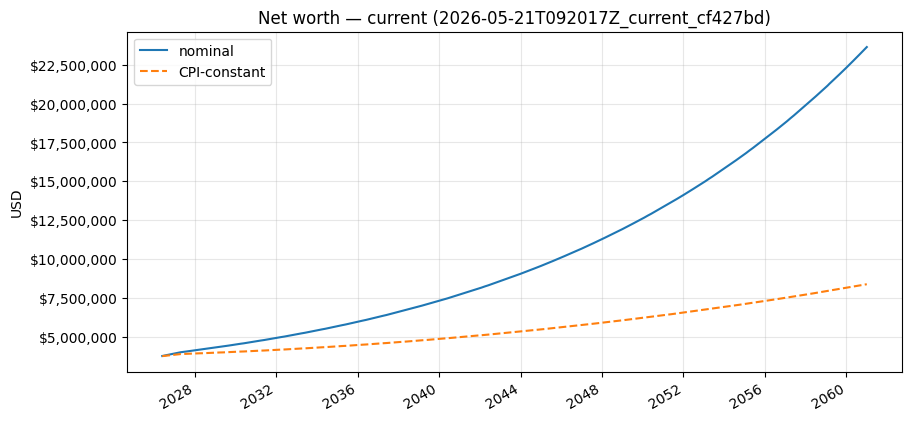

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(nw.index, nw["nominal"], label="nominal")
if nw["cpi_constant"].notna().any():
    ax.plot(nw.index, nw["cpi_constant"], label="CPI-constant", linestyle="--")
ax.set_title(
    f"Net worth — {run_meta.loc[0, 'scenario_name']} "
    f"({RUN_FILE.stem})"
)
ax.set_ylabel("USD")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.grid(True, alpha=0.3)
ax.legend()
fig.autofmt_xdate()
plt.show()


## Income by category

Income flows are transfers _out of_ accounts with `kind = 'income'`. Subkinds are bucketed:

- **salary** — `salary`
- **investment** — `interest`, `dividend`, `capital_gain`
- **other** — `ss_benefit`, `pension`, `rental`, `other_income`


In [6]:
income_sql = """
SELECT s.month,
       CASE a.subkind
         WHEN 'salary'        THEN 'salary'
         WHEN 'interest'      THEN 'investment'
         WHEN 'dividend'      THEN 'investment'
         WHEN 'capital_gain'  THEN 'investment'
         ELSE 'other'
       END AS category,
       SUM(te.amount) AS cents
FROM transfer_event te
JOIN simulation_step s ON s.id = te.step_id
JOIN account a         ON a.id = te.from_account
WHERE a.kind = 'income'
GROUP BY s.month, category
"""
income_raw = pd.read_sql(income_sql, con)
income_raw["month"] = pd.to_datetime(income_raw["month"])
income = (
    income_raw.pivot_table(
        index="month", columns="category", values="cents",
        aggfunc="sum", fill_value=0,
    )
    .reindex(columns=["salary", "investment", "other"], fill_value=0)
    / 100
)
income["total"] = income.sum(axis=1)
income.head()


category,salary,investment,other,total
month,,,,
2026-05-31,10574.6,9842.55,2825.0,23242.15
2026-06-30,10574.6,9931.45,2825.0,23331.05
2026-07-31,10574.6,10020.78,2825.0,23420.38
2026-08-31,10574.6,10110.47,2825.0,23510.07
2026-09-30,10574.6,10207.26,2825.0,23606.86


In [7]:
priors = pd.read_sql(
    "SELECT year, bucket, amount FROM prior_tax_activity",
    con,
)
# bucket -> income category
_PRIOR_CAT = {"ss_benefit": "other", "ordinary": "salary", "tax_free": "investment"}
priors["category"] = priors["bucket"].map(_PRIOR_CAT)
priors["amount"] = priors["amount"] / 100  # cents -> dollars
priors_by_year = (
    priors.pivot_table(index="year", columns="category", values="amount",
                       aggfunc="sum", fill_value=0)
    .reindex(columns=["salary", "investment", "other"], fill_value=0)
)

income_yearly = income.groupby(income.index.year).sum()
income_yearly.index.name = "year"
# Fold priors into the same year totals (priors cover pre-sim YTD activity).
for cat in ["salary", "investment", "other"]:
    if cat in priors_by_year.columns:
        income_yearly[cat] = income_yearly[cat].add(priors_by_year[cat], fill_value=0)
income_yearly["total"] = income_yearly[["salary", "investment", "other"]].sum(axis=1)
income_yearly.style.format("${:,.0f}")


category,salary,investment,other,total
year,,,,
2026,"$137,470","$125,669","$33,900","$297,038"
2027,"$47,586","$133,067","$53,676","$234,329"
2028,$0,"$143,764","$67,802","$211,567"
2029,$0,"$154,764","$67,802","$222,566"
2030,$0,"$166,418","$67,802","$234,220"
2031,$0,"$179,653","$67,802","$247,455"
2032,$0,"$194,572","$67,802","$262,375"
2033,$0,"$210,357","$67,802","$278,159"
2034,$0,"$227,057","$67,802","$294,859"


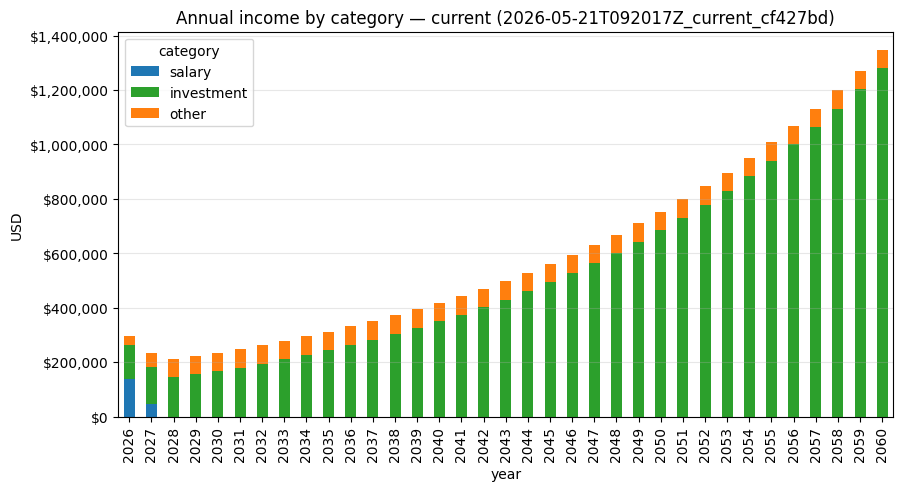

In [8]:
categories = ["salary", "investment", "other"]
fig, ax = plt.subplots(figsize=(10, 5))
income_yearly[categories].plot(
    kind="bar", stacked=True, ax=ax,
    color=["#1f77b4", "#2ca02c", "#ff7f0e"],
)
ax.set_title(
    f"Annual income by category — {run_meta.loc[0, 'scenario_name']} "
    f"({RUN_FILE.stem})"
)
ax.set_xlabel("year")
ax.set_ylabel("USD")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.grid(True, axis="y", alpha=0.3)
ax.legend(title="category")
plt.show()
